# Omni Market Intelligence: app markets from telco traffic

How many people in **BSD** ordered food on **Ride-hailing Green** today, compared with **Ride-hailing Lime**?
The apps won't tell each other. A mobile network can estimate it for every brand at once, from traffic alone.

The funnel this notebook rebuilds:

```
telco DAU ─► app users (host lookup) ─► drivers vs customers ─► service (Ride/Car/Food/Mart…) ─► transacted?
```

> I built the production version at Eureka AI (2021–2024) for super-app, ride-hailing and e-commerce clients
> in Jakarta, Bangkok, Kuala Lumpur and Singapore, and it grew from 5% to 70% of company revenue.
> **Here everything is simulated and every brand is anonymised**; the method is the real one.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from omni.sim import simulate, BRANDS, SERVICES, SVC_HOURS, bumps
from omni import model as m
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
SCALE = 150          # one simulated person = 150 real subscribers → about 30M daily users in Jabodetabek

## 1. Simulate a day on the network
200,000 people on a 2 km hex grid over Jabodetabek. Each one sleeps somewhere, 60% commute to work, and some use one or more of four apps.

In [2]:
cells, people, sessions = simulate()
print(f'{len(cells):,} hexes · {len(people):,} people · {len(sessions):,} app sessions')
sessions.head()

1,354 hexes · 200,000 people · 262,884 app sessions


,person,brand,driver,service,hour,cell,txn,host_service,host_pay,host_partner,kb,duration_s,move_km_60m
0,11,green,True,Driver,8,1143,False,Driver,False,True,394.399397,116.431969,2.752624
1,11,green,True,Driver,16,1001,False,Driver,False,True,250.820358,205.067788,1.392639
2,11,green,True,Driver,9,767,False,Driver,False,False,388.089669,59.452261,0.598574
3,11,green,True,Driver,12,978,False,Home,False,True,380.191620,233.828625,6.734212
4,11,green,True,Driver,11,133,False,Driver,False,True,445.664994,174.699614,2.950451


Each session is what the network sees: hour, cell, a (noisy) **service host** hint, whether a **payment** or **driver-partner** endpoint was hit, bytes, duration, and how far the phone moved in the next hour.

## 2. Labelled panel
Models are trained on a 10% **panel** of people whose app receipts are known (in production: a consented research panel). Everything is then scored on the other 90%.

## 3. Drivers vs customers
Per person and brand: sessions, distinct cells, active hours, share of partner-endpoint traffic, distance moved.

In [3]:
users = m.user_features(sessions)
panel = m.split_panel(users)
users['driver_pred'], driver_rep = m.fit_driver(users, panel)
s = sessions.merge(users[['person', 'brand', 'driver_pred']], on=['person', 'brand'])
ride_users = users[users.brand.isin(['green', 'lime'])]
print(f"driver precision {driver_rep['precision']:.2f} · recall {driver_rep['recall']:.2f}")
print(f"drivers as share of ride-hailing app users: {ride_users.driver_pred.mean():.1%}")

driver precision 0.94 · recall 0.89
drivers as share of ride-hailing app users: 7.0%


## 4. Which service?
A session's host hint is wrong or ambiguous 22% of the time, so the model also uses bytes, duration and movement afterwards (a Ride moves you; Food doesn't).

In [4]:
cust = s[~s.driver_pred].reset_index(drop=True)
cpanel = m.split_panel(cust)
cust['service_pred'], svc_rep = m.fit_service(cust, cpanel)
for k, r in svc_rep.items():
    print(f"{k:13s} accuracy {r['accuracy']:.2f} · " + ' · '.join(f"{c} F1 {r[c]['f1-score']:.2f}" for c in r if c not in ('accuracy', 'macro avg', 'weighted avg')))

e-commerce    accuracy 0.86 · Electronics F1 0.84 · Fashion F1 0.88 · Groceries F1 0.87 · Home F1 0.83
ride-hailing  accuracy 0.89 · Car F1 0.84 · Driver F1 0.68 · Food F1 0.92 · Mart F1 0.85 · Ride F1 0.92


## 5. Did the session end in an order?
The threshold is set so the predicted transaction rate matches the panel's rate. That keeps the market totals unbiased even though single sessions are uncertain.

In [5]:
cust['txn_pred'], txn_rep = m.fit_txn(cust, cpanel)
print(f"AUC {txn_rep['auc']:.3f} · precision {txn_rep['precision']:.2f} · recall {txn_rep['recall']:.2f}")
print(f"sessions with an order: true {txn_rep['true_rate']:.1%} · predicted {txn_rep['pred_rate']:.1%}")
dau = cust.groupby(['person', 'brand']).txn_pred.any()
print(f"customers who ordered at least once today: {dau.mean():.1%}")

AUC 0.965 · precision 0.78 · recall 0.80
sessions with an order: true 12.0% · predicted 12.3%
customers who ordered at least once today: 23.9%


## 6. The funnel

In [6]:
rows = []
for b, cfg in BRANDS.items():
    u = users[users.brand == b]; c = cust[cust.brand == b]
    rows.append(dict(brand=cfg['name'], app_dau=len(u) * SCALE, drivers=u.driver_pred.sum() * SCALE,
                     customers=(~u.driver_pred).sum() * SCALE,
                     ordering_customers=c[c.txn_pred].person.nunique() * SCALE))
funnel = pd.DataFrame(rows).set_index('brand')
print(f'telco DAU (Jabodetabek, simulated): {len(people) * SCALE / 1e6:.0f}M')
(funnel / 1e6).round(2).rename(columns=lambda x: x + ' (M)')

telco DAU (Jabodetabek, simulated): 30M


,app_dau (M),drivers (M),customers (M),ordering_customers (M)
brand,,,,
Ride-hailing Green,5.26,0.35,4.90,1.28
Ride-hailing Lime,4.14,0.31,3.83,1.01
E-commerce Orange,4.74,0.00,4.74,1.00
E-commerce Teal,3.13,0.00,3.13,0.67


## 7. The question clients pay for
Food: daily users who ordered, by area, Green vs Lime.

,Green (K),Lime (K),lime_share
area,,,
BSD & Tangerang Selatan,33,49,60%
Tangerang,30,29,49%
Jakarta Utara,16,15,48%
Jakarta Barat,41,36,47%
Cikarang,29,25,46%
Bekasi,50,42,46%
Jakarta Timur,51,38,43%
Depok,47,35,42%
Bogor,33,23,41%


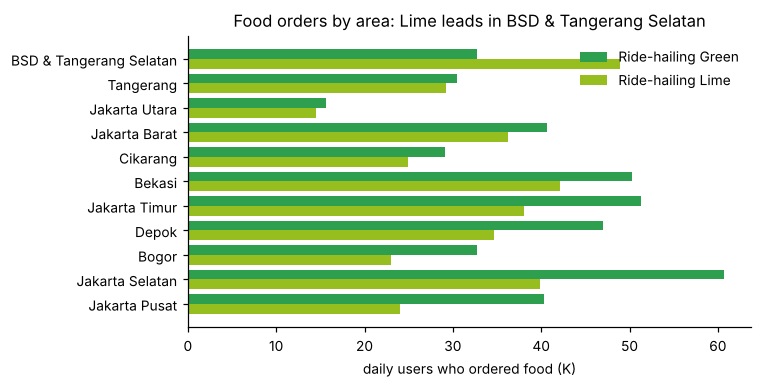

In [7]:
cust['area'] = cells.area.values[cust.cell]
food = cust[(cust.service_pred == 'Food') & cust.txn_pred & cust.brand.isin(['green', 'lime'])]
tab = food.groupby(['area', 'brand']).person.nunique().unstack().mul(SCALE)
tab['lime_share'] = tab.lime / (tab.green + tab.lime)
tab = tab.sort_values('lime_share', ascending=False)
display((tab[['green', 'lime']] / 1e3).round(0).astype(int).rename(columns={'green': 'Green (K)', 'lime': 'Lime (K)'}).join(tab.lime_share.map('{:.0%}'.format)))

fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(tab))
ax.barh(y - .2, tab.green / 1e3, .4, color=np.array(BRANDS['green']['color']) / 255, label='Ride-hailing Green')
ax.barh(y + .2, tab.lime / 1e3, .4, color=np.array(BRANDS['lime']['color']) / 255, label='Ride-hailing Lime')
ax.set_yticks(y, tab.index); ax.invert_yaxis(); ax.set_xlabel('daily users who ordered food (K)')
ax.legend(frameon=False); ax.set_title('Food orders by area: Lime leads in BSD & Tangerang Selatan')
plt.tight_layout(); plt.savefig('../docs/food-by-area.png'); plt.show()

## 8. Export for the 3D map

In [8]:
s2 = s.merge(cust[['person', 'brand', 'hour', 'cell', 'service_pred', 'txn_pred']].drop_duplicates(['person', 'brand', 'hour', 'cell']),
              on=['person', 'brand', 'hour', 'cell'], how='left')
s2['service_pred'] = s2.service_pred.fillna('Driver'); s2['txn_pred'] = s2.txn_pred.fillna(False).astype(bool)
brands = {b: dict(name=c['name'], kind=c['kind'], color=c['color']) for b, c in BRANDS.items()}
services = {b: list(SERVICES[c['kind']]) for b, c in BRANDS.items()}
svc_hours = {v: np.round(bumps(h), 4).tolist() for v, h in SVC_HOURS.items()}
metrics = dict(driver=driver_rep, txn=txn_rep, service={k: round(r['accuracy'], 3) for k, r in svc_rep.items()},
               txn_dau=float(dau.mean()))
trips = {b: m.driver_trips(cells, s2, b, n=220) for b in ('green', 'lime')}
m.export_web('../web/data/omni.json', cells, people, s2, brands, services, svc_hours, metrics, SCALE, trips)
import os; print(f"{os.path.getsize('../web/data/omni.json') / 1e6:.1f} MB")

1.5 MB


## Takeaways
- Four signals carry most of the weight: the host hint, payment endpoints, bytes/duration, and movement after the session.
- Single sessions are uncertain (precision around 0.8), but calibrated totals per area are what clients buy, and those are stable.
- In production: PySpark over clickstream and cell records, models tracked in MLflow, refreshed daily per city.